[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/nlavadodatasci/atd-megaf-fiabilidade/blob/main/T1_taxa_de_falha/T1_taxa_de_falha.ipynb)

# T1 — Taxa de falha e padrões de falha

**ATD — MEGAF 2026/27 · Atividade de Fiabilidade · Tema T1**

A taxa de falha $h(t)$ diz, para um componente que chegou vivo ao instante $t$, com que frequência falha logo a seguir. Este *notebook* mostra como estimá-la a partir de tempos até à falha, usando os dados da aula.

**Como usar:** execute as células por ordem (Shift+Enter). As primeiras secções estão resolvidas, com dados da aula ou com exemplos inventados, para mostrar o método. A última secção, **A sua vez**, lê os dados da instalação e deixa pistas: o trabalho do grupo começa aí. O capítulo deste tema no documento de apoio explica cada passo.

## 1. Ler os dados da aula

In [1]:
import os, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

REPO = "https://raw.githubusercontent.com/nlavadodatasci/atd-megaf-fiabilidade/main/dados/"

def obter(ficheiro):
    """Vai buscar o ficheiro ao repositório. Se falhar, abre uma janela
    para o escolher no seu computador."""
    if not os.path.exists(ficheiro):
        try:
            urllib.request.urlretrieve(REPO + ficheiro, ficheiro)
        except Exception:
            from google.colab import files
            print("Escolha no seu computador o ficheiro", ficheiro)
            carregados = files.upload()
            if ficheiro not in carregados:               # veio com outro nome: renomeia
                os.rename(list(carregados)[0], ficheiro)
    return ficheiro

aula = pd.read_excel(obter("tempo_falhas_aula.xlsx"), sheet_name="tempo_falhas", usecols="A:B")
t = aula.iloc[:, 1].dropna().to_numpy()      # tempos até à falha da aula (horas)
print("Número de tempos:", len(t), "  MTBF:", round(t.mean(), 2))

Número de tempos: 9998   MTBF: 8738.14


## 2. Taxa de falha empírica, por classes

A ideia é a de uma tabela de frequências, com duas colunas a mais. Para cada classe de tempo:

- **em risco**: quantas unidades ainda funcionavam no início da classe;
- **falhas**: quantas falharam dentro da classe;
- **horas de funcionamento**: quantas horas, ao todo, as unidades em risco funcionaram dentro da classe (as que falharam a meio só contam até falharem);
- **taxa de falha** $= \dfrac{\text{falhas}}{\text{horas de funcionamento}}$ (falhas por hora de funcionamento).

Repare na diferença para a densidade $f(t)$: na densidade divide-se pelo número **total** de unidades; na taxa de falha só contam as que **ainda estavam vivas**.

Em Excel, as horas de funcionamento de uma classe podem aproximar-se por (em risco $-$ falhas/2) $\times$ amplitude, como se as falhas acontecessem todas a meio da classe.

In [2]:
def taxa_falha_empirica(tempos, k):
    limites = np.linspace(0, tempos.max(), k + 1)
    linhas = []
    for inicio, fim in zip(limites[:-1], limites[1:]):
        em_risco = (tempos > inicio).sum()
        falhas = ((tempos > inicio) & (tempos <= fim)).sum()
        horas = (np.clip(tempos, inicio, fim) - inicio).sum()    # horas vividas dentro da classe
        linhas.append({"inicio": round(inicio), "fim": round(fim), "em_risco": em_risco,
                       "falhas": falhas, "horas_func": round(horas), "taxa": falhas / horas})
    return pd.DataFrame(linhas)

tab = taxa_falha_empirica(t, k=14)
tab

,inicio,fim,em_risco,falhas,horas_func,taxa
0,0,6192,9998,5046,44314746,0.000114
1,6192,12384,4952,2532,22008495,0.000115
2,12384,18576,2420,1230,10706952,0.000115
3,18576,24769,1190,599,5317593,0.000113
4,24769,30961,591,322,2577524,0.000125
5,30961,37153,269,137,1187217,0.000115
6,37153,43345,132,65,597264,0.000109
7,43345,49537,67,33,315915,0.000104
8,49537,55729,34,13,160113,0.000081
9,55729,61921,21,11,83478,0.000132


Compare a coluna `taxa` com $\lambda = 1/\text{MTBF}$ calculado na aula. Nas primeiras classes os valores andam à volta de $\lambda$. Nas últimas há muito poucas unidades em risco e a estimativa fica instável: é um problema que vai encontrar também nos dados da instalação.

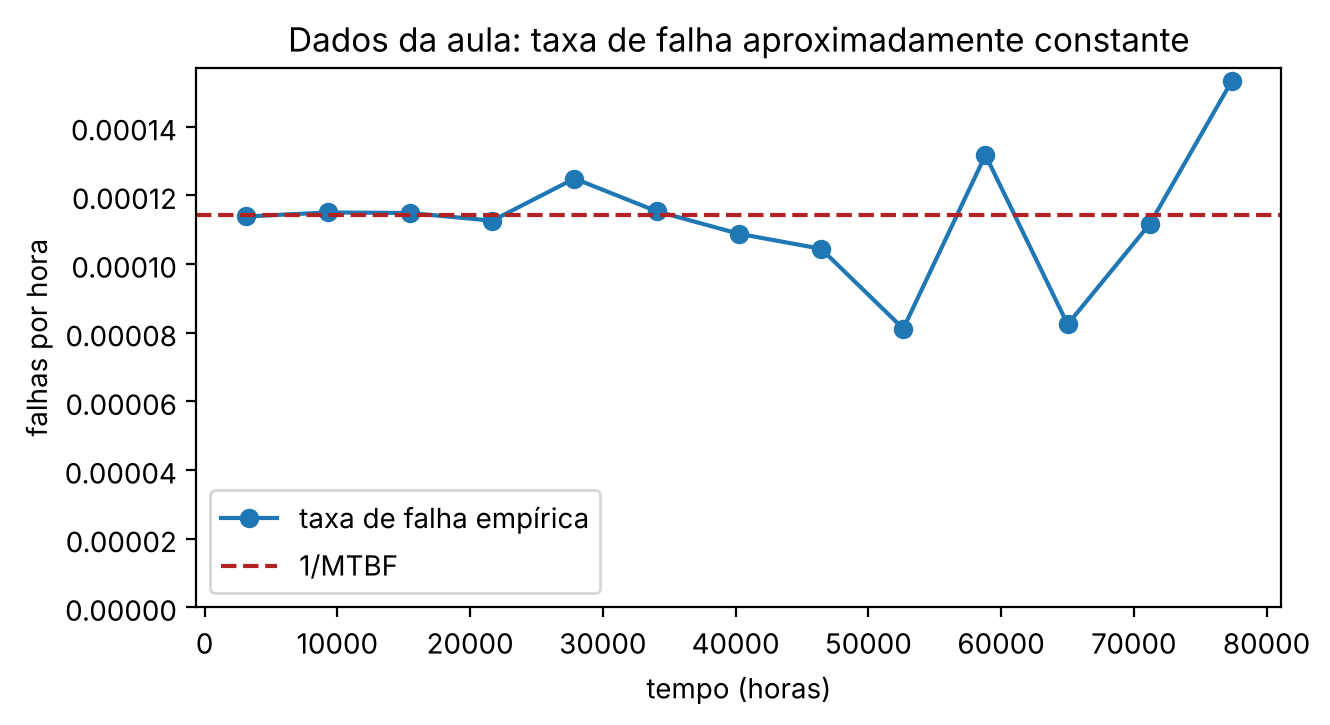

In [3]:
lam = 1 / t.mean()
centro = (tab["inicio"] + tab["fim"]) / 2

plt.figure(figsize=(7, 3.5))
plt.plot(centro[:-1], tab["taxa"][:-1], "o-", label="taxa de falha empírica")
plt.axhline(lam, color="firebrick", ls="--", label="1/MTBF")
plt.xlabel("tempo (horas)"); plt.ylabel("falhas por hora"); plt.legend(); plt.ylim(0)
plt.title("Dados da aula: taxa de falha aproximadamente constante")
plt.show()

(A última classe ficou fora do gráfico: tem uma única unidade em risco.)

## 3. Taxa de falha de um modelo

Se tiver um modelo ajustado, a taxa de falha calcula-se diretamente por $h(t) = f(t)/R(t)$. Em `scipy`: `modelo.pdf(x) / modelo.sf(x)`.

O gráfico seguinte usa três distribuições Weibull com parâmetros **inventados**, só para mostrar as três formas possíveis.

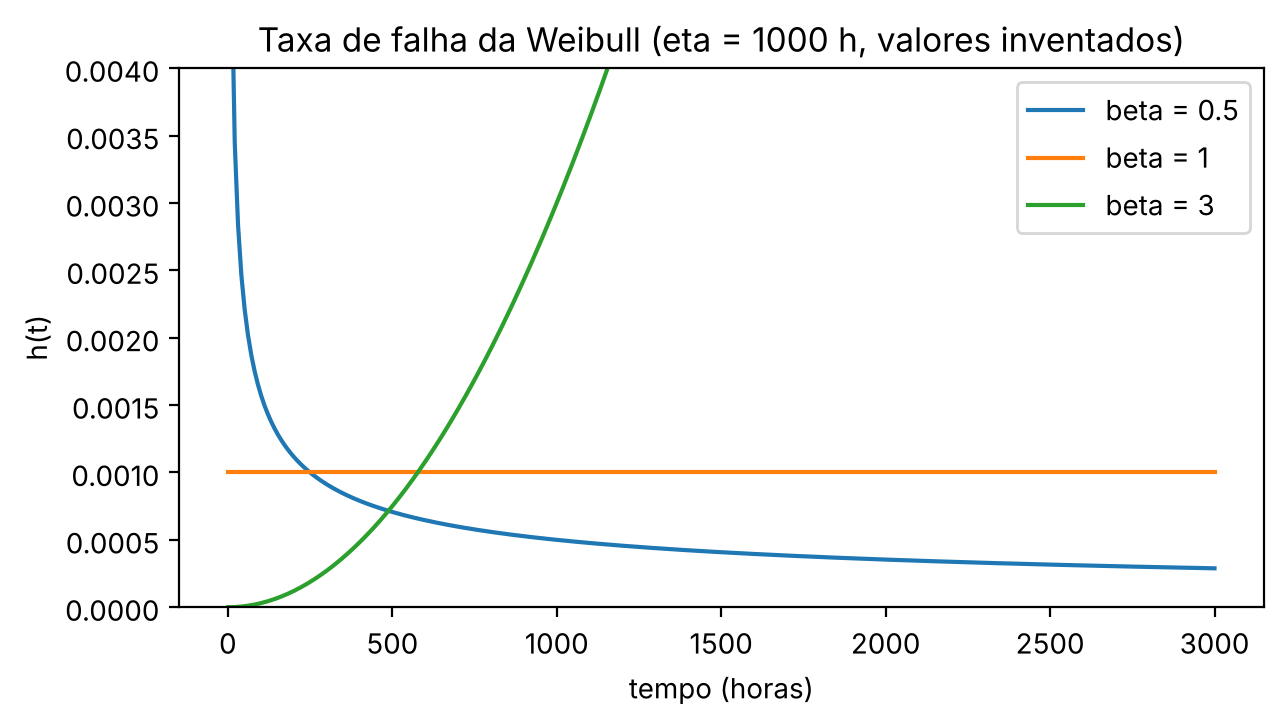

In [4]:
x = np.linspace(1, 3000, 300)
plt.figure(figsize=(7, 3.5))
for beta in [0.5, 1, 3]:
    modelo = stats.weibull_min(beta, scale=1000)
    plt.plot(x, modelo.pdf(x) / modelo.sf(x), label=f"beta = {beta}")
plt.ylim(0, 0.004); plt.xlabel("tempo (horas)"); plt.ylabel("h(t)"); plt.legend()
plt.title("Taxa de falha da Weibull (eta = 1000 h, valores inventados)")
plt.show()

## 4. A sua vez

A célula seguinte lê os ensaios de vida da instalação. A partir daqui o trabalho é do grupo. Pistas:

1. Calcule a taxa de falha empírica de cada componente. Com 50 unidades, 14 classes são demasiadas: experimente 5 ou 6 e veja o que muda.
2. A taxa cresce, decresce ou mantém-se? Olhe para a tendência geral e desconfie da última classe.
3. Ajuste um modelo a cada componente (secção 4 do documento de apoio e *notebook* `00_comum`) e sobreponha a taxa de falha do modelo à empírica.
4. Associe cada componente a um dos padrões da Fig. 2 do documento base.
5. Para cada padrão, que política de manutenção faz sentido? Substituir preventivamente uma peça cuja taxa de falha não cresce ajuda em alguma coisa?

In [5]:
ensaios = pd.read_excel(obter("dados_fiabilidade.xlsx"), sheet_name="ensaios_vida")
print(list(ensaios["componente"].unique()))

componente = "Interruptor"                     # troque pelo componente a estudar
tc = ensaios[ensaios["componente"] == componente]["tempo_ate_falha_h"].to_numpy()
print(componente, "- número de tempos:", len(tc))

# taxa_falha_empirica(tc, k=...)

['Interruptor', 'Transformador', 'QGBT', 'Gerador', 'Controlador']
Interruptor - número de tempos: 50
